# JASON pivots — individual pivots & wave-distance statistics

The shipped JASON `high_pivot` / `low_pivot` are **vote-weighted averages** of
several actual pivots (real high/low price levels on the series). That blend is
the right object for a *deviation* feature, but it is the wrong object for
studying the **geometry of the swings**: to describe up-waves (low pivot → next
high pivot) and down-waves (high pivot → next low pivot) we need the
**individual** pivots — and preferably only the ones that carry weight.

**What this notebook does**

1. Re-uses JASON's *exact* pivot-selection logic — the running-extreme scan, the
   `min_days` validity mask, and top-N-by-vote-count from
   `_calculate_metrics_for_window` — but **keeps the individual pivots and their
   vote weights** instead of averaging them.
2. Aggregates those votes across every trailing window into a single
   **global importance** per bar → the structurally dominant swing highs/lows.
3. Plots price with **▲ up-triangles at low pivots** and **▼ down-triangles at
   high pivots**, sized by importance.
4. Builds an alternating zig-zag of the significant pivots and measures the
   **up-wave / down-wave** distributions (magnitude & duration).

Data: **Binance BTCUSDT perpetual, 1h bars**, via the single lake read path
(`src.data.query.get`). Pivot params match the JASON default: `lookback=7`
days, `n_pivots=5`, `min_days=1`.

In [24]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd()
while not (REPO_ROOT / "src").is_dir() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import plotly.graph_objects as go
from numba import jit

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 110, "axes.grid": True,
    "grid.alpha": 0.25, "axes.edgecolor": "#888",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

from src.data.query import get
from src.signals.jason import compute_jason_vectorized, CANDLE_SECONDS, TRADING_DAYS_PER_YEAR

SYMBOL, TF = "btcusdt", "1h"
START = "2021-01-01"          # last few years; the lake carries BTC 1h from 2021+
LOOKBACK, N_PIVOTS, MIN_DAYS = 7, 5, 1

ohlc = get("perps", "binance", SYMBOL, "bars", TF, start=START)
print(f"{SYMBOL} {TF}: {ohlc.shape[0]:,} bars   {ohlc.index[0]} -> {ohlc.index[-1]}")
ohlc.head(3)

btcusdt 1h: 48,678 bars   2021-01-01 00:00:00 -> 2026-07-22 05:00:00


,open,high,low,close,volume
ts,,,,,
2021-01-01 00:00:00,28948.19,29055.00,28706.00,29015.00,8037.588
2021-01-01 01:00:00,29015.00,29546.42,28975.46,29448.40,19543.401
2021-01-01 02:00:00,29443.65,29500.00,29159.16,29237.06,10049.720


## 1 — The individual-pivot extractor

JASON selects pivots like this (crypto branch of `_calculate_metrics_for_window`),
for a trailing window of `window_size = lookback_candles + 1` bars ending at each
bar:

- **Running extreme.** For every position `i` in the window, the *high pivot* is
  `argmax(high[i:])` (ties → most recent bar); the *low pivot* is `argmin(low[i:])`.
- **Validity mask.** Only positions older than `min_days` may vote
  (`time_in_years > min_days_in_years`) — this keeps the freshest ~`min_days`
  of bars from being counted as confirmed pivots.
- **Vote → weight.** Each valid position casts one vote for its running-extreme
  bar. A bar's **vote count is its weight**: the extreme that holds the record
  over the longest stretch wins the most votes.
- **Top-N.** Per window, only the `n_pivots` most-voted highs (and lows) survive.

The shipped feature then blends those top-N into one price. **Here we keep them.**
The function below is a faithful numba transcription of that selection; it returns,
for each bar, a global **importance** = the total top-N vote weight that bar ever
received as a high pivot (and separately as a low pivot) across all windows.

In [25]:
@jit(nopython=True, cache=False)
def _accumulate_pivot_votes(highs, lows, lookback_candles,
                            min_days_in_years, rel_time_in_years, n_pivots):
    '''Global per-bar pivot importance, faithful to JASON's window selection.

    Returns (high_votes, low_votes, high_hits, low_hits):
      * *_votes: total top-N vote weight the bar accrued as a high / low pivot,
        summed across every trailing window it appeared in;
      * *_hits:  number of distinct windows in which the bar was a top-N pivot.
    '''
    N = len(highs)
    window_size = lookback_candles + 1
    high_votes = np.zeros(N)
    low_votes = np.zeros(N)
    high_hits = np.zeros(N)
    low_hits = np.zeros(N)

    hpi = np.empty(window_size, np.int64)
    lpi = np.empty(window_size, np.int64)
    h_counts = np.empty(window_size, np.int64)
    l_counts = np.empty(window_size, np.int64)

    for end_i in range(lookback_candles, N):
        start = end_i - lookback_candles

        # running argmax(high)/argmin(low) over [i, end] within the window; ties
        # resolve to the most-recent bar (strict >, matching the engine).
        last_max = window_size - 1
        last_min = window_size - 1
        for i in range(window_size - 1, -1, -1):
            if highs[start + i] > highs[start + last_max]:
                last_max = i
            if lows[start + i] < lows[start + last_min]:
                last_min = i
            hpi[i] = last_max
            lpi[i] = last_min

        # tally votes from valid (old-enough) positions only
        for p in range(window_size):
            h_counts[p] = 0
            l_counts[p] = 0
        for i in range(window_size):
            if rel_time_in_years[i] > min_days_in_years:
                h_counts[hpi[i]] += 1
                l_counts[lpi[i]] += 1

        # top-N pivots by vote count, accumulated to their absolute bar index
        h_order = np.argsort(h_counts)
        taken = 0
        for r in range(window_size - 1, -1, -1):
            p = h_order[r]
            if h_counts[p] <= 0:
                break
            high_votes[start + p] += h_counts[p]
            high_hits[start + p] += 1.0
            taken += 1
            if taken >= n_pivots:
                break

        l_order = np.argsort(l_counts)
        taken = 0
        for r in range(window_size - 1, -1, -1):
            p = l_order[r]
            if l_counts[p] <= 0:
                break
            low_votes[start + p] += l_counts[p]
            low_hits[start + p] += 1.0
            taken += 1
            if taken >= n_pivots:
                break

    return high_votes, low_votes, high_hits, low_hits


def extract_pivot_importance(ohlc, freq, lookback, n_pivots, min_days,
                             asset_class="crypto"):
    '''Wrap the vote accumulator with the same annualization constants the engine
    uses, and return a per-bar frame of pivot importance.'''
    t_min = CANDLE_SECONDS[freq]
    days_in_year = float(TRADING_DAYS_PER_YEAR.get(asset_class, 365))
    s_in_year = days_in_year * 24.0 * 3600.0          # crypto: 24h/day
    lookback_candles = int(lookback * 24 * 60 * 60 // t_min)
    window_size = lookback_candles + 1

    # identical to compute_jason_vectorized's crypto branch
    t_sec = np.arange(window_size * t_min, 0, -t_min, dtype=np.float64)
    t_sec = np.maximum(t_sec, t_min)
    rel_time_in_years = t_sec / s_in_year
    min_days_in_years = (min_days / days_in_year) - (t_min / s_in_year)

    highs = ohlc["high"].to_numpy(np.float64)
    lows = ohlc["low"].to_numpy(np.float64)
    hv, lv, hh, lh = _accumulate_pivot_votes(
        highs, lows, lookback_candles, min_days_in_years, rel_time_in_years, n_pivots)

    return pd.DataFrame(
        {"high_votes": hv, "low_votes": lv, "high_hits": hh, "low_hits": lh},
        index=ohlc.index,
    )

piv = extract_pivot_importance(ohlc, TF, LOOKBACK, N_PIVOTS, MIN_DAYS)
print("bars with any high-pivot weight:", int((piv['high_votes'] > 0).sum()))
print("bars with any low-pivot  weight:", int((piv['low_votes'] > 0).sum()))
piv[piv["high_votes"] > 0].sort_values("high_votes", ascending=False).head(8)

bars with any high-pivot weight: 7239
bars with any low-pivot  weight: 6944


,high_votes,low_votes,high_hits,low_hits
ts,,,,
2023-11-09 14:00:00,14089.0,0.0,169.0,0.0
2023-10-23 22:00:00,14089.0,0.0,169.0,0.0
2023-08-08 21:00:00,14089.0,0.0,169.0,0.0
2022-02-10 17:00:00,14089.0,0.0,169.0,0.0
2022-09-27 12:00:00,14089.0,0.0,169.0,0.0
2023-03-30 02:00:00,14089.0,0.0,169.0,0.0
2025-12-22 12:00:00,14089.0,0.0,169.0,0.0
2021-07-26 01:00:00,14089.0,0.0,169.0,0.0


## 2 — Blended vs individual pivots (a sanity contrast)

The shipped feature collapses the top-N pivots into a single moving `high_pivot`
/ `low_pivot`. Below, the blended lines (from `compute_jason_vectorized`) are
drawn over the individual high pivots (▼) and low pivots (▲) we just extracted —
the blend threads *through* the cloud of real pivots, which is exactly why it is
unsuitable for measuring the distance *between* them.

Interactive (Plotly): **drag to zoom, double-click to reset, click legend items
to toggle series.** Marker size ∝ pivot importance (vote weight).

In [26]:
feat = compute_jason_vectorized(ohlc.copy(), SYMBOL.upper(), TF,
                                lookback=LOOKBACK, n_pivots=N_PIVOTS, min_days=MIN_DAYS)

zoom_days = 180
z0 = ohlc.index[-1] - pd.Timedelta(days=zoom_days)
m = piv.index >= z0
c = ohlc.loc[m, "close"]

# individual pivots in the zoom window (any weight), sized by importance
hp = piv[m & (piv["high_votes"] > 0)]
lp = piv[m & (piv["low_votes"] > 0)]
def _sz(v, lo=5, hi=22):
    v = v.to_numpy(float)
    if len(v) == 0: return v
    r = (v - v.min()) / (np.ptp(v) + 1e-9)
    return lo + r * (hi - lo)

fb = feat[feat.index >= z0]
fig = go.Figure()
fig.add_scattergl(x=c.index, y=c.values, name="close", line=dict(color="#111", width=1))
fig.add_scattergl(x=fb.index, y=fb["high_pivot"], name="blended high_pivot",
                  line=dict(color="#c0392b", width=1), opacity=0.6)
fig.add_scattergl(x=fb.index, y=fb["low_pivot"], name="blended low_pivot",
                  line=dict(color="#2471a3", width=1), opacity=0.6)
fig.add_scattergl(x=hp.index, y=ohlc.loc[hp.index, "high"], name="high pivot (indiv.)",
                  mode="markers", marker=dict(symbol="triangle-down", color="#c0392b",
                  size=_sz(hp["high_votes"]), line=dict(color="white", width=0.5)),
                  customdata=hp["high_votes"], hovertemplate="high %{y:.0f} · w=%{customdata:.0f}<extra></extra>")
fig.add_scattergl(x=lp.index, y=ohlc.loc[lp.index, "low"], name="low pivot (indiv.)",
                  mode="markers", marker=dict(symbol="triangle-up", color="#2471a3",
                  size=_sz(lp["low_votes"]), line=dict(color="white", width=0.5)),
                  customdata=lp["low_votes"], hovertemplate="low %{y:.0f} · w=%{customdata:.0f}<extra></extra>")
fig.update_layout(template="plotly_white", height=520, hovermode="x unified",
                  title=f"BTCUSDT 1h — individual pivots vs blended JASON pivot (last {zoom_days}d)",
                  legend=dict(orientation="h", y=1.02, yanchor="bottom"),
                  margin=dict(l=50, r=20, t=60, b=40))
fig.show()

## 3 — Significant pivots & the zig-zag

Every bar that ever won a top-N vote is a candidate pivot, but most carry little
weight. We keep only the **significant** pivots — those whose total vote weight
sits above a percentile `Q` of the non-zero weights — then collapse consecutive
same-type pivots to the more extreme one to obtain a clean **alternating**
high/low sequence. Consecutive `(low → high)` pairs are **up-waves**;
`(high → low)` pairs are **down-waves**.

`Q` is the one real knob here: raise it for fewer, more dominant swings; lower it
to include minor structure. Start at the median (`Q = 0.5`).

In [27]:
Q = 0.50   # keep pivots above this percentile of non-zero vote weight

def significant_pivots(piv, ohlc, q):
    hv = piv["high_votes"]; lv = piv["low_votes"]
    h_thr = np.quantile(hv[hv > 0], q)
    l_thr = np.quantile(lv[lv > 0], q)
    events = []  # (bar_pos, kind, price, weight, ts)
    pos = {ts: i for i, ts in enumerate(ohlc.index)}
    for ts, w in hv[hv >= h_thr].items():
        events.append((pos[ts], "H", float(ohlc.at[ts, "high"]), float(w), ts))
    for ts, w in lv[lv >= l_thr].items():
        events.append((pos[ts], "L", float(ohlc.at[ts, "low"]), float(w), ts))
    events.sort(key=lambda e: e[0])
    return events, h_thr, l_thr

def collapse_zigzag(events):
    '''Alternating H/L sequence: among consecutive same-type pivots keep the
    more extreme (highest high / lowest low).'''
    seq = []
    for ev in events:
        if seq and seq[-1][1] == ev[1]:
            keep_new = (ev[1] == "H" and ev[2] > seq[-1][2]) or \
                       (ev[1] == "L" and ev[2] < seq[-1][2])
            if keep_new:
                seq[-1] = ev
        else:
            seq.append(ev)
    return seq

events, h_thr, l_thr = significant_pivots(piv, ohlc, Q)
seq = collapse_zigzag(events)
print(f"significant pivots: {len(events)}  ->  zig-zag turning points: {len(seq)}")
print(f"vote-weight thresholds (Q={Q}):  high>={h_thr:.0f}  low>={l_thr:.0f}")

significant pivots: 7106  ->  zig-zag turning points: 3128
vote-weight thresholds (Q=0.5):  high>=87  low>=84


## 4 — The pivot map (full history)

Price over the whole sample with the significant zig-zag pivots as triangles —
**▲ up-triangle = low pivot, ▼ down-triangle = high pivot** — connected by the
zig-zag that defines the waves.

The static figure is unreadable over 5+ years, so this is **interactive**: drag a
box to zoom into any stretch, use the range-slider under the axis to scrub,
double-click to reset. A standalone copy is written to the repo root
(`pivot_waves_map.html`) — open it in a browser to explore offline.

In [28]:
seq_ts = [e[4] for e in seq]
seq_px = [e[2] for e in seq]
H = [e for e in seq if e[1] == "H"]
L = [e for e in seq if e[1] == "L"]

fig = go.Figure()
fig.add_scattergl(x=ohlc.index, y=ohlc["close"], name="close",
                  line=dict(color="#111", width=0.7), opacity=0.75)
fig.add_scattergl(x=seq_ts, y=seq_px, name="zig-zag",
                  line=dict(color="#f39c12", width=0.8), opacity=0.7)
fig.add_scattergl(x=[e[4] for e in H], y=[e[2] for e in H], name="high pivot",
                  mode="markers", customdata=[e[3] for e in H],
                  marker=dict(symbol="triangle-down", color="#c0392b", size=9,
                              line=dict(color="white", width=0.5)),
                  hovertemplate="high %{y:.0f} · w=%{customdata:.0f}<extra></extra>")
fig.add_scattergl(x=[e[4] for e in L], y=[e[2] for e in L], name="low pivot",
                  mode="markers", customdata=[e[3] for e in L],
                  marker=dict(symbol="triangle-up", color="#2471a3", size=9,
                              line=dict(color="white", width=0.5)),
                  hovertemplate="low %{y:.0f} · w=%{customdata:.0f}<extra></extra>")
fig.update_layout(template="plotly_white", height=620, hovermode="x unified",
                  title=f"BTCUSDT 1h — significant JASON pivots (Q={Q}, lookback={LOOKBACK}d)",
                  legend=dict(orientation="h", y=1.02, yanchor="bottom"),
                  margin=dict(l=55, r=20, t=60, b=40))
fig.update_yaxes(type="log", title="price (log)")
fig.update_xaxes(rangeslider=dict(visible=True))

out_html = REPO_ROOT / "pivot_waves_map.html"
fig.write_html(str(out_html), include_plotlyjs=True, full_html=True)
print(f"interactive map -> {out_html}")
fig.show()

interactive map -> /home/sam.ahou/projects/operator/pivot_waves_map.html


## 5 — Wave-distance distributions

Each consecutive turning-point pair is a wave. We measure it three ways:

- **raw % move** — `expm1(ln(P_to / P_from))`. Simple, but **regime-contaminated**:
  a 5% swing in the 2021 bull is ordinary; in a calm 2023 stretch it is huge. The
  raw distribution mixes regimes and mostly reflects the vol backdrop.
- **vol-normalized magnitude (σ)** — `ln(P_to / P_from) / (σ · √t)`, where `σ` is
  the **ambient annualized realized vol** going into the wave (trailing
  Garman-Klass QV over the prior `lookback` window, the *same* estimator JASON
  uses) and `t` is the wave duration in years. This is exactly a JASON-style
  **z**: how many sigmas the swing represents once both the vol regime *and* the
  wave's own length are divided out. Comparable across 2021 and 2023.
- **duration** — hours / days between the two pivots.

Each distribution is annotated with its stats (n, mean, median, p10/p25/p75/p90,
max); the **solid line is the median**, dotted lines are **p10 / p90**.

**Choose the sample window** with `DIST_YEARS` below: the number of years of
history (counted back from the last bar) the distribution is built over — set it
to `None` for the full ~5.5y. Pivots are always extracted on the full series
(clean warmup); only the *waves counted into the distribution* are windowed.

distribution window: 2025-07-22 -> 2026-07-20  (0.99y, DIST_YEARS=1)
waves: 571  (286 up, 285 down)   [6 without ambient vol -> excluded from σ plots]


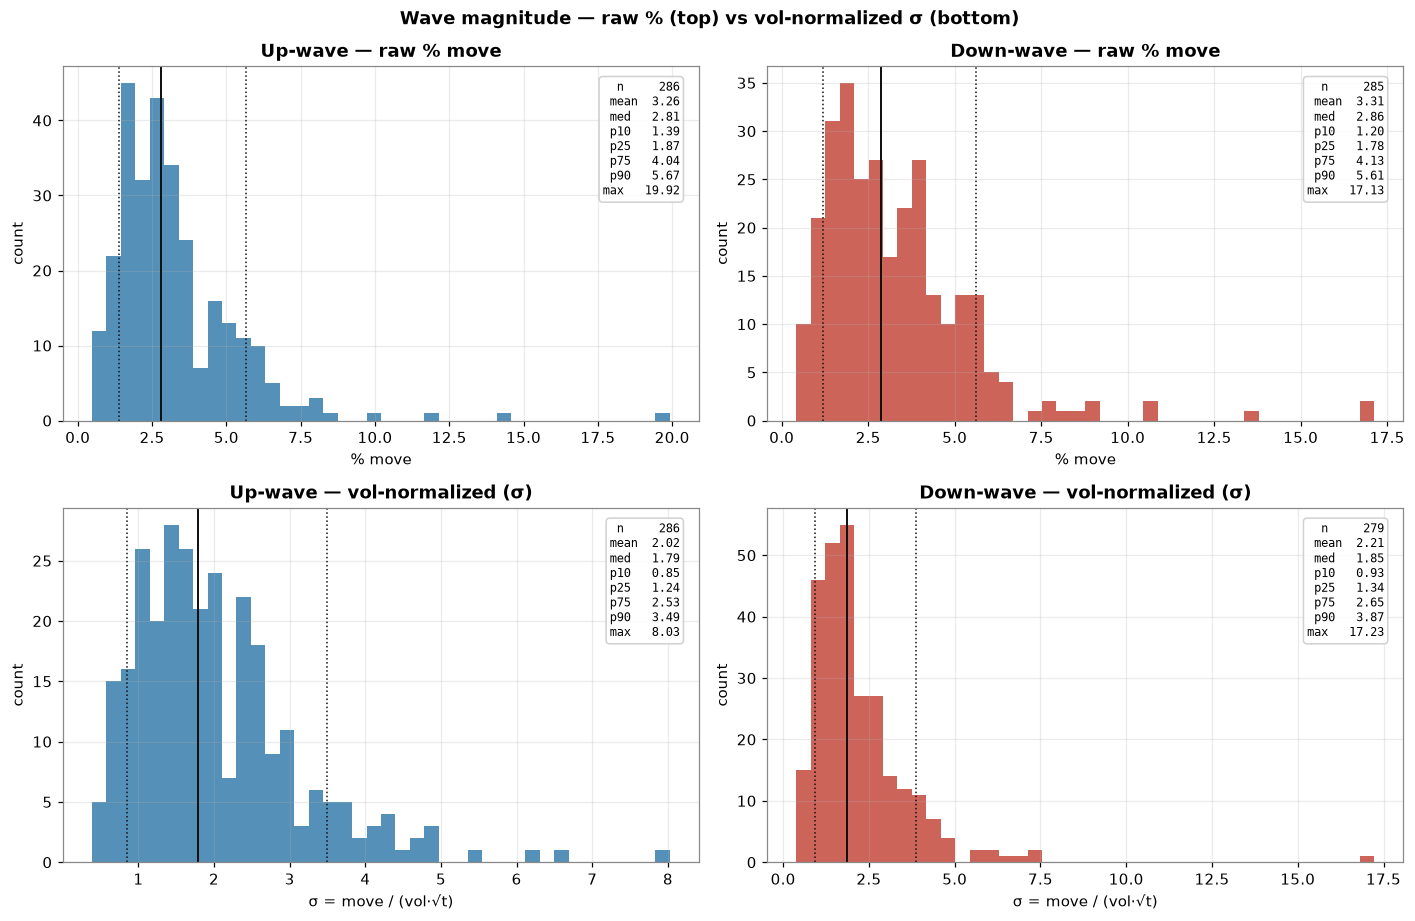

In [29]:
# Ambient annualized realized vol per bar: trailing Garman-Klass QV over the prior
# `lookback` window, ending strictly BEFORE the bar (causal). Same GK/OCHL estimator
# JASON uses (no gap term), annualized on the crypto 24/7 clock.
BARS_PER_YEAR = 365.0 * 24.0            # 1h crypto
VOL_W = LOOKBACK * 24                   # trailing window in bars (7d)

o, h, l, c_ = (ohlc[k].to_numpy(np.float64) for k in ("open", "high", "low", "close"))
M, mm, X = np.log(h / o), np.log(l / o), np.log(c_ / o)
gk_qv = 0.511 * (M - mm) ** 2 - 0.019 * (X * (M + mm) - 2 * M * mm) - 0.383 * X ** 2
vol_ann = np.sqrt(
    pd.Series(gk_qv, index=ohlc.index).shift(1)
      .rolling(VOL_W, min_periods=VOL_W // 2).mean() * BARS_PER_YEAR
).to_numpy()

waves = []
for a, b in zip(seq, seq[1:]):
    if a[1] == b[1]:
        continue
    kind = "up" if (a[1] == "L" and b[1] == "H") else "down"
    log_move = np.log(b[2] / a[2])
    dur_h = (b[0] - a[0])               # bars == hours at 1h
    t_years = dur_h / BARS_PER_YEAR
    sig = vol_ann[a[0]]                 # ambient vol at the wave's start pivot
    z_move = log_move / (sig * np.sqrt(t_years)) if (sig and t_years > 0) else np.nan
    waves.append({
        "kind": kind, "from_ts": a[4], "to_ts": b[4],
        "from_px": a[2], "to_px": b[2],
        "log_move": log_move, "pct_move": np.expm1(log_move) * 100.0,
        "abs_pct": abs(np.expm1(log_move)) * 100.0,
        "vol_ann": sig, "z_move": z_move, "abs_z": abs(z_move),
        "dur_hours": dur_h, "dur_days": dur_h / 24.0,
    })
waves = pd.DataFrame(waves)

# --- choose how much history the distribution uses ------------------------- #
# Duration of the sample window, in years, counted back from the last bar.
# Set to None to use the full loaded history (2021+ -> ~5.5y).
DIST_YEARS = 1          # e.g. 1.0, 2.0, 0.5 ...

if DIST_YEARS is not None:
    cutoff = ohlc.index[-1] - pd.Timedelta(days=365.25 * DIST_YEARS)
    waves = waves[waves["from_ts"] >= cutoff]
span = (waves["from_ts"].max() - waves["from_ts"].min())
print(f"distribution window: {waves['from_ts'].min():%Y-%m-%d} -> {waves['from_ts'].max():%Y-%m-%d}"
      f"  ({span.days / 365.25:.2f}y, DIST_YEARS={DIST_YEARS})")

up = waves[waves["kind"] == "up"]
dn = waves[waves["kind"] == "down"]
n_bad = int(waves["abs_z"].isna().sum())
print(f"waves: {len(waves)}  ({len(up)} up, {len(dn)} down)"
      + (f"   [{n_bad} without ambient vol -> excluded from σ plots]" if n_bad else ""))


def hist_stats(ax, data, title, xlabel, color):
    data = np.asarray(data, float)
    data = data[np.isfinite(data)]
    ax.hist(data, bins=40, color=color, alpha=0.78)
    p10, p25, p50, p75, p90 = np.percentile(data, [10, 25, 50, 75, 90])
    ax.axvline(p50, color="#111", ls="-", lw=1.3)
    ax.axvline(p10, color="#111", ls=":", lw=1.0)
    ax.axvline(p90, color="#111", ls=":", lw=1.0)
    txt = (f"n     {len(data)}\nmean  {data.mean():.2f}\nmed   {p50:.2f}\n"
           f"p10   {p10:.2f}\np25   {p25:.2f}\np75   {p75:.2f}\n"
           f"p90   {p90:.2f}\nmax   {data.max():.2f}")
    ax.text(0.97, 0.96, txt, transform=ax.transAxes, ha="right", va="top",
            fontsize=8, family="monospace",
            bbox=dict(boxstyle="round", fc="white", ec="#ccc", alpha=0.9))
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("count")


fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
hist_stats(axes[0, 0], up["abs_pct"], "Up-wave — raw % move", "% move", "#2471a3")
hist_stats(axes[0, 1], dn["abs_pct"], "Down-wave — raw % move", "% move", "#c0392b")
hist_stats(axes[1, 0], up["abs_z"], "Up-wave — vol-normalized (σ)", "σ = move / (vol·√t)", "#2471a3")
hist_stats(axes[1, 1], dn["abs_z"], "Down-wave — vol-normalized (σ)", "σ = move / (vol·√t)", "#c0392b")
fig.suptitle("Wave magnitude — raw % (top) vs vol-normalized σ (bottom)", fontweight="bold")
plt.tight_layout(); plt.show()

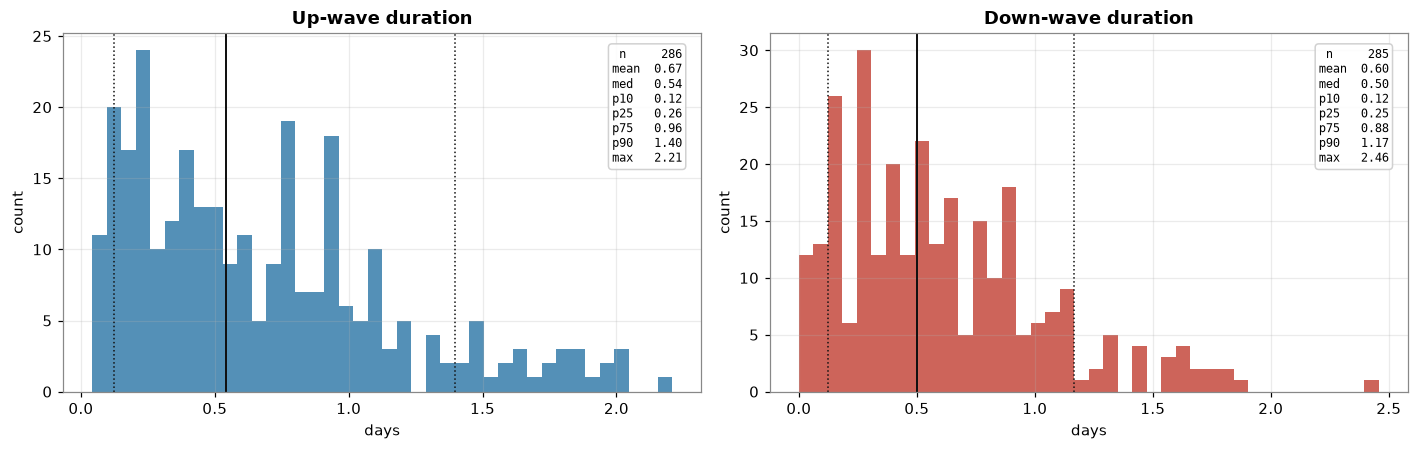

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
hist_stats(axes[0], up["dur_days"], "Up-wave duration", "days", "#2471a3")
hist_stats(axes[1], dn["dur_days"], "Down-wave duration", "days", "#c0392b")
plt.tight_layout(); plt.show()

In [31]:
pcts = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]

def describe(s):
    s = s.dropna()
    out = {"n": len(s), "mean": s.mean(), "std": s.std()}
    out.update({f"p{int(p*100):02d}": s.quantile(p) for p in pcts})
    out["max"] = s.max()
    return pd.Series(out)

summary = pd.DataFrame({
    "up_%":    describe(up["abs_pct"]),
    "down_%":  describe(dn["abs_pct"]),
    "up_σ":    describe(up["abs_z"]),
    "down_σ":  describe(dn["abs_z"]),
    "up_dur_d":   describe(up["dur_days"]),
    "down_dur_d": describe(dn["dur_days"]),
}).round(2)
print("Wave summary statistics  (magnitude in raw %, vol-normalized σ, and duration in days)")
print(summary.to_string())

Wave summary statistics  (magnitude in raw %, vol-normalized σ, and duration in days)
        up_%  down_%    up_σ  down_σ  up_dur_d  down_dur_d
n     286.00  285.00  286.00  279.00    286.00      285.00
mean    3.26    3.31    2.02    2.21      0.67        0.60
std     2.12    2.21    1.11    1.52      0.49        0.44
p05     1.05    0.96    0.73    0.80      0.12        0.08
p10     1.39    1.20    0.85    0.93      0.12        0.12
p25     1.87    1.78    1.24    1.34      0.26        0.25
p50     2.81    2.86    1.79    1.85      0.54        0.50
p75     4.04    4.13    2.53    2.65      0.96        0.88
p90     5.67    5.61    3.49    3.87      1.40        1.17
p95     6.64    6.30    4.15    4.54      1.74        1.53
max    19.92   17.13    8.03   17.23      2.21        2.46


### Did the vol-normalization work?

If `σ = move / (vol·√t)` has done its job, wave magnitude should no longer grow
with duration — the `√t` and the vol regime are divided out. The left panel shows
the raw % magnitude climbing with duration (the tell-tale `√t` shape); the right
panel shows the σ magnitude roughly **flat** in duration, confirming the
normalization removed both the duration and the vol-regime effects.

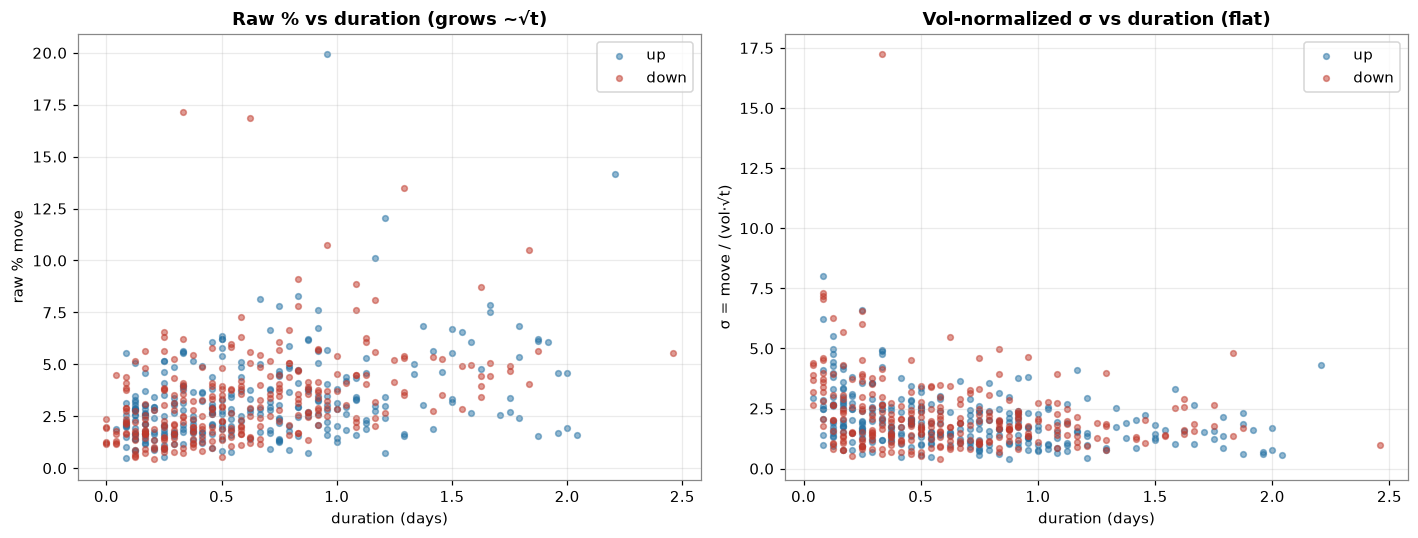

In [32]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5))
axL.scatter(up["dur_days"], up["abs_pct"], s=14, color="#2471a3", alpha=0.5, label="up")
axL.scatter(dn["dur_days"], dn["abs_pct"], s=14, color="#c0392b", alpha=0.5, label="down")
axL.set_xlabel("duration (days)"); axL.set_ylabel("raw % move")
axL.set_title("Raw % vs duration (grows ~√t)"); axL.legend()

axR.scatter(up["dur_days"], up["abs_z"], s=14, color="#2471a3", alpha=0.5, label="up")
axR.scatter(dn["dur_days"], dn["abs_z"], s=14, color="#c0392b", alpha=0.5, label="down")
axR.set_xlabel("duration (days)"); axR.set_ylabel("σ = move / (vol·√t)")
axR.set_title("Vol-normalized σ vs duration (flat)"); axR.legend()
plt.tight_layout(); plt.show()

## 6 — JASON z-scores at significant pivots

JASON emits two deviation z-scores per bar (both in σ·√t units):

- **`z_up`** = `ln(close / low_pivot) / σ√t` — how far above the (blended) low
  pivot price sits. It peaks at a **swing top**: the σ-height of the up-move that
  just completed.
- **`z_dn`** = `ln(high_pivot / close) / σ√t` — how far below the high pivot. It
  peaks at a **swing bottom**: the σ-depth of the completed down-move.

Sampling these *at the significant pivots* answers a sharper question than the
wave-magnitude section: **at what σ-stretch do swings actually turn?** Below,
`z_up` is taken at the significant **high** pivots (tops) and `z_dn` at the
significant **low** pivots (bottoms), against the unconditional all-bars
distribution for contrast. The same `DIST_YEARS` window applies.

z sampled at 286 high pivots (tops) and 286 low pivots (bottoms)


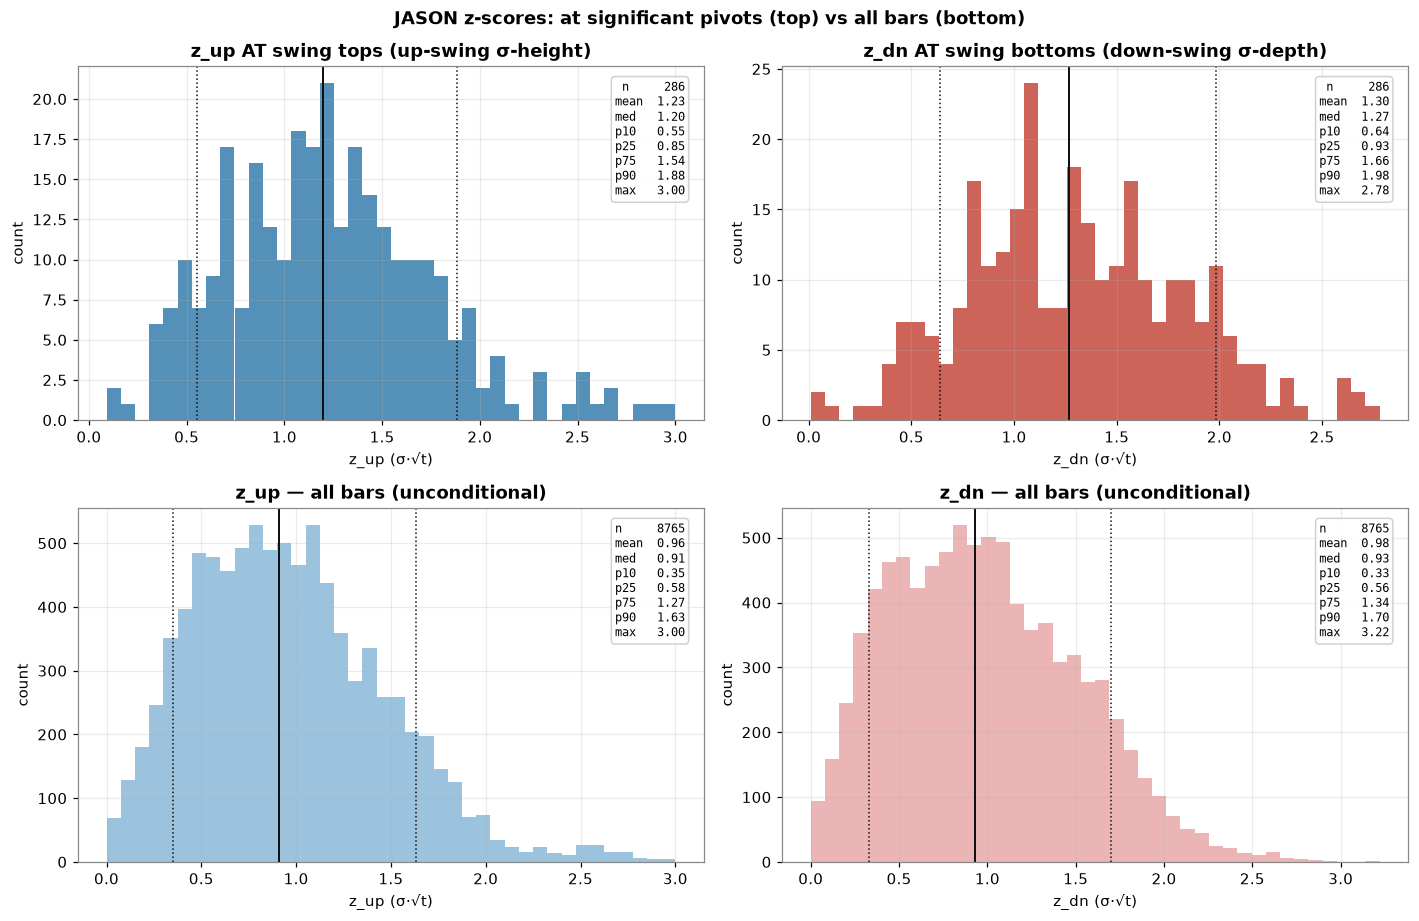

In [33]:
# JASON's own z-scores (blended-pivot deviation), aligned to the distribution window.
win_start = waves["from_ts"].min()
zc = feat[["z_dn", "z_up"]]
zc = zc[zc.index >= win_start]

# significant-pivot timestamps from the zig-zag turning points, within the window
Hts = [e[4] for e in seq if e[1] == "H" and e[4] >= win_start and e[4] in feat.index]
Lts = [e[4] for e in seq if e[1] == "L" and e[4] >= win_start and e[4] in feat.index]

z_up_top = feat.loc[Hts, "z_up"]     # up-swing σ-height, at swing tops
z_dn_bot = feat.loc[Lts, "z_dn"]     # down-swing σ-depth, at swing bottoms
print(f"z sampled at {len(Hts)} high pivots (tops) and {len(Lts)} low pivots (bottoms)")

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
hist_stats(axes[0, 0], z_up_top, "z_up AT swing tops (up-swing σ-height)", "z_up (σ·√t)", "#2471a3")
hist_stats(axes[0, 1], z_dn_bot, "z_dn AT swing bottoms (down-swing σ-depth)", "z_dn (σ·√t)", "#c0392b")
hist_stats(axes[1, 0], zc["z_up"], "z_up — all bars (unconditional)", "z_up (σ·√t)", "#7fb3d5")
hist_stats(axes[1, 1], zc["z_dn"], "z_dn — all bars (unconditional)", "z_dn (σ·√t)", "#e6a0a0")
fig.suptitle("JASON z-scores: at significant pivots (top) vs all bars (bottom)", fontweight="bold")
plt.tight_layout(); plt.show()

In [34]:
z_summary = pd.DataFrame({
    "z_up @ tops":    describe(z_up_top),
    "z_dn @ bottoms": describe(z_dn_bot),
    "z_up all bars":  describe(zc["z_up"]),
    "z_dn all bars":  describe(zc["z_dn"]),
}).round(2)
print("JASON z-score statistics  (σ·√t units)")
print(z_summary.to_string())

JASON z-score statistics  (σ·√t units)
      z_up @ tops  z_dn @ bottoms  z_up all bars  z_dn all bars
n          286.00          286.00        8765.00        8765.00
mean         1.23            1.30           0.96           0.98
std          0.53            0.53           0.50           0.52
p05          0.43            0.48           0.24           0.23
p10          0.55            0.64           0.35           0.33
p25          0.85            0.93           0.58           0.56
p50          1.20            1.27           0.91           0.93
p75          1.54            1.66           1.27           1.34
p90          1.88            1.98           1.63           1.70
p95          2.11            2.16           1.82           1.88
max          3.00            2.78           3.00           3.22


## Where this goes next

This is the scaffold, not the conclusion. Natural next steps:

- **Sensitivity to `Q` and `lookback`** — the wave distribution is conditional on
  both. Sweep them and show how the swing-size distribution deforms; find the
  regime where pivots are stable.
- **Compare to a parameter-free zig-zag** (e.g. a fixed-% ATR filter) to check
  the JASON-weighted pivots aren't just re-deriving a trivial threshold.
- **Conditioning** — up- vs down-wave asymmetry, magnitude autocorrelation
  (does a big up-wave predict a big retrace?), regime by realized vol.
- **Cross-sectional** — run the extractor across the perp universe and ask
  whether the swing-size distribution is an asset constant or a market-wide one.
- If any of this earns a place, promote the extractor into a small reusable
  research lib rather than leaving it in-notebook.